# Final Data Science Capstone Project
## Drivers of High Income in US Census Data – Analysis, Prediction and a Fairness & Limitations Audit
**Task 6 – Yuva Intern | AI/ML Research Specialist Internship**

**Dataset:** UCI *Adult* (Census Income) dataset – 48,842 records from the 1994 US Census, 14 attributes, target = annual income above or below $50,000.

## 1. Problem Definition
**Problem statement.** A workforce-development agency wants to understand *which factors are associated with earning above $50K*, *how strongly*, and whether a predictive model can help it **plan programmes at the group level** (for example where to focus upskilling support). Because income models can encode social bias, the agency also needs an **audit of fairness, bias and limitations** before any use.

**Objectives**
1. Prepare and explore the data, documenting quality problems and how they were handled.
2. Quantify the relationships with statistical tests – with effect sizes, context and candidate explanations, not just p-values.
3. Build and compare machine-learning models and evaluate them with appropriate metrics (including calibration and uncertainty).
4. Audit the model's behaviour across sex, race and age groups and discuss bias, proxies and limitations.
5. Convert findings into practical, responsible recommendations and future scope.

**Scope.** Descriptive and predictive analysis on a historical snapshot. Out of scope: causal claims, individual-level decisions (hiring, lending, etc.).

**Success criteria.** (a) Test ROC-AUC ≥ 0.85; (b) calibrated probabilities (Brier score reported); (c) subgroup performance and fairness gaps reported with confidence intervals; (d) every statistical result accompanied by an effect size and an interpretation.

**Expected outcomes.** Education, age, hours worked, marital/household status and capital gains will be strong predictors; a model including sex or race is not needed to predict well, and any gap by group must be examined rather than assumed away.

In [1]:
import os, json, warnings, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("images", exist_ok=True)
SEED = 42; rng = np.random.default_rng(SEED); M = {}
f = lambda v: float(np.round(v, 4))
def save(name): plt.tight_layout(); plt.savefig(f"images/{name}.png", dpi=130); plt.show()

cols = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation","relationship","race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv"
try: raw = pd.read_csv("data/adult_raw.csv", header=None, names=cols, skipinitialspace=True)
except FileNotFoundError:
    raw = pd.read_csv(URL, header=None, names=cols, skipinitialspace=True); raw.to_csv("data/adult_raw.csv", index=False, header=False)
print(raw.shape); raw.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Data Collection, Quality Audit and Preparation

**Source & provenance.** Extracted by Barry Becker from the 1994 US Census database and published in the UCI Machine Learning Repository. Records are individuals aged 16+ with positive income and hours; `fnlwgt` is the census sampling weight.

In [2]:
M.update(rows_raw=len(raw), cols=raw.shape[1])
dups = int(raw.duplicated().sum()); print("Exact duplicate rows:", dups)
q = {c: int((raw[c] == "?").sum()) for c in ["workclass", "occupation", "native_country"]}; print("Missing ('?') counts:", q)
print({k: f"{v/len(raw):.2%}" for k, v in q.items()})
print("capital_gain == 99999 (top-coded):", int((raw.capital_gain == 99999).sum()), "| capital_gain > 0:", f"{(raw.capital_gain > 0).mean():.1%}", "| capital_loss > 0:", f"{(raw.capital_loss > 0).mean():.1%}")
print("hours_per_week == 99:", int((raw.hours_per_week == 99).sum()), "| age == 90 (top-coded):", int((raw.age == 90).sum()))
print("\nRepresentation:"); print(raw.race.value_counts(normalize=True).round(4).to_dict()); print(raw.sex.value_counts(normalize=True).round(4).to_dict())
M.update(dups=dups, miss=q, top_gain=int((raw.capital_gain == 99999).sum()), pos_gain=f((raw.capital_gain > 0).mean()), pos_loss=f((raw.capital_loss > 0).mean()),
         race_share=raw.race.value_counts(normalize=True).round(4).to_dict(), sex_share=raw.sex.value_counts(normalize=True).round(4).to_dict(), age90=int((raw.age == 90).sum()))

Exact duplicate rows: 52
Missing ('?') counts: {'workclass': 2799, 'occupation': 2809, 'native_country': 857}
{'workclass': '5.73%', 'occupation': '5.75%', 'native_country': '1.75%'}
capital_gain == 99999 (top-coded): 244 | capital_gain > 0: 8.3% | capital_loss > 0: 4.7%
hours_per_week == 99: 137 | age == 90 (top-coded): 55

Representation:
{'White': 0.855, 'Black': 0.0959, 'Asian-Pac-Islander': 0.0311, 'Amer-Indian-Eskimo': 0.0096, 'Other': 0.0083}
{'Male': 0.6685, 'Female': 0.3315}


**Is the missingness random?** Missing `workclass` and `occupation` could reflect non-working or unusual cases rather than random omission. A chi-square test checks whether income differs between records with and without a missing occupation.

In [3]:
df = raw.drop_duplicates().reset_index(drop=True).replace("?", np.nan)
df["occ_missing"] = df.occupation.isna()
t = pd.crosstab(df.occ_missing, df.income); chi, p, _, _ = stats.chi2_contingency(t)
rm = (df[df.occ_missing].income == ">50K").mean(); rk = (df[~df.occ_missing].income == ">50K").mean()
print(f"High-income rate: occupation missing {rm:.1%} (n={df.occ_missing.sum():,}) vs present {rk:.1%} | chi2 = {chi:.1f}, p = {p:.2e}")
print("Mean hours/week when occupation missing:", round(df[df.occ_missing].hours_per_week.mean(), 1), "vs", round(df[~df.occ_missing].hours_per_week.mean(), 1))
M.update(occmiss_rate=f(rm), occpres_rate=f(rk), occmiss_chi=f(chi), occmiss_n=int(df.occ_missing.sum()),
         occmiss_hours=f(df[df.occ_missing].hours_per_week.mean()), occpres_hours=f(df[~df.occ_missing].hours_per_week.mean()))

High-income rate: occupation missing 9.4% (n=2,805) vs present 24.8% | chi2 = 342.5, p = 1.83e-76
Mean hours/week when occupation missing: 31.8 vs 41.0


**Decision.** Missingness is clearly *not* random (those records have much lower income and fewer hours), so rows are **not** dropped and values are **not** imputed with the mode; instead `Unknown` is kept as its own category so the model can learn from the pattern. This is documented as a limitation because it can hide real heterogeneity.

In [4]:
df = df.drop(columns="occ_missing")
for c in ["workclass", "occupation", "native_country"]: df[c] = df[c].fillna("Unknown")
df["high"] = (df.income == ">50K").astype(int)

# ---- feature engineering ----
df["age_band"] = pd.cut(df.age, [16, 24, 34, 44, 54, 64, 100], labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"])
df["hours_band"] = pd.cut(df.hours_per_week, [0, 34, 44, 100], labels=["Part-time (<35)", "Full-time (35-44)", "Overtime (45+)"])
df["edu_group"] = pd.cut(df.education_num, [0, 8, 9, 12, 13, 16], labels=["No HS diploma", "HS graduate", "Some college/Assoc", "Bachelors", "Postgraduate"])
df["marital_group"] = df.marital_status.map({"Married-civ-spouse": "Married", "Married-AF-spouse": "Married", "Never-married": "Never married",
                                              "Divorced": "Div/Sep/Widowed", "Separated": "Div/Sep/Widowed", "Widowed": "Div/Sep/Widowed", "Married-spouse-absent": "Div/Sep/Widowed"})
df["workclass_group"] = df.workclass.map({"Private": "Private", "Self-emp-not-inc": "Self-employed", "Self-emp-inc": "Self-employed", "Local-gov": "Government",
                                          "State-gov": "Government", "Federal-gov": "Government", "Without-pay": "Other", "Never-worked": "Other", "Unknown": "Unknown"})
df["country_grp"] = np.where(df.native_country == "United-States", "United-States", np.where(df.native_country == "Mexico", "Mexico", np.where(df.native_country == "Unknown", "Unknown", "Other")))
df["has_gain"] = (df.capital_gain > 0).astype(int); df["has_loss"] = (df.capital_loss > 0).astype(int)
df["gain_cat"] = pd.cut(df.capital_gain, [-1, 0, 4999, 10**9], labels=["None", "Under 5000", "5000 or more"]).astype(str)
df["log_gain"] = np.log1p(df.capital_gain); df["age2"] = df.age ** 2 / 100
df.to_csv("data/adult_clean.csv", index=False)
M.update(rows=len(df), removed=len(raw) - len(df), high_rate=f(df.high.mean()), high_n=int(df.high.sum()))
print(f"{len(raw):,} -> {len(df):,} rows | high-income (>50K) rate = {df.high.mean():.2%} ({df.high.sum():,} people)  -> imbalance ratio 1 : {(1-df.high.mean())/df.high.mean():.1f}")

48,842 -> 48,790 rows | high-income (>50K) rate = 23.94% (11,681 people)  -> imbalance ratio 1 : 3.2


**Feature-engineering rationale:** education is already numeric (`education_num`) so the text column is dropped; age bands and a quadratic age term capture the career-stage curve; hours are banded into part/full/overtime; marital and workclass levels are grouped for readability; capital gains are heavily zero-inflated (only a small share of people have any) so both a flag and a log value are kept; `fnlwgt` is a sampling weight, not a property of the person, so it is not used as a predictor.

## 3. Exploratory Data Analysis

In [5]:
def rate(col):
    g = df.groupby(col, observed=True).agg(n=("high", "size"), high_rate=("high", "mean")).round(4); return g
for c in ["sex", "race", "edu_group", "age_band", "hours_band", "marital_group", "workclass_group"]:
    print(f"--- {c} ---"); print(rate(c).to_string(), "\n")
M["rates"] = {c: rate(c).reset_index().astype({c: str}).to_dict("records") for c in ["sex", "race", "edu_group", "age_band", "hours_band", "marital_group", "workclass_group"]}
occ = rate("occupation").sort_values("high_rate", ascending=False); print(occ.to_string()); M["occ"] = occ.reset_index().to_dict("records")

--- sex ---
            n  high_rate
sex                     
Female  16176     0.1094
Male    32614     0.3039 

--- race ---
                        n  high_rate
race                                
Amer-Indian-Eskimo    470     0.1170
Asian-Pac-Islander   1517     0.2696
Black                4683     0.1209
Other                 406     0.1232
White               41714     0.2541 

--- edu_group ---
                        n  high_rate
edu_group                           
No HS diploma        6399     0.0572
HS graduate         15770     0.1586
Some college/Assoc  14524     0.2063
Bachelors            8013     0.4132
Postgraduate         4084     0.6139 

--- age_band ---
              n  high_rate
age_band                  
17-24      8409     0.0111
25-34     12564     0.1683
35-44     12184     0.3328
45-54      8765     0.3940
55-64      4782     0.3216
65+        2086     0.2047 

--- hours_band ---
                       n  high_rate
hours_band                         
Part-ti

## 4. Statistical Analysis – With Context, Effect Sizes and Candidate Explanations
Conventions: α = 0.05; effect sizes reported next to every p-value (with 48,000 rows, nearly everything is "significant", so *size* is what matters); families of tests are corrected with the Holm method. Explanations offered for trends are **hypotheses** consistent with the data, not proven causes.

### 4.1 Income gap between men and women: two-proportion z-test

In [6]:
m = df[df.sex == "Male"].high; w = df[df.sex == "Female"].high
cnt = np.array([m.sum(), w.sum()]); nobs = np.array([len(m), len(w)])
z, p = proportions_ztest(cnt, nobs); lo, hi = confint_proportions_2indep(cnt[0], nobs[0], cnt[1], nobs[1], method="wald"); h = proportion_effectsize(cnt[0]/nobs[0], cnt[1]/nobs[1])
print(f"Men: {cnt[0]:,}/{nobs[0]:,} = {m.mean():.2%} | Women: {cnt[1]:,}/{nobs[1]:,} = {w.mean():.2%}")
print(f"Gap = {(m.mean()-w.mean())*100:.1f} pp, 95% CI ({lo*100:.1f}, {hi*100:.1f}); z = {z:.1f}, p = {p:.1e}; Cohen's h = {h:.2f}; ratio = {m.mean()/w.mean():.2f}x")
M.update(men_rate=f(m.mean()), women_rate=f(w.mean()), men_n=int(nobs[0]), women_n=int(nobs[1]), men_c=int(cnt[0]), women_c=int(cnt[1]), gap_pp=f((m.mean()-w.mean())*100),
         gap_lo=f(lo*100), gap_hi=f(hi*100), z_sex=f(z), h_sex=f(h), ratio_sex=f(m.mean()/w.mean()))

Men: 9,912/32,614 = 30.39% | Women: 1,769/16,176 = 10.94%
Gap = 19.5 pp, 95% CI (18.8, 20.1); z = 47.4, p = 0.0e+00; Cohen's h = 0.49; ratio = 2.78x


**Context & possible reasons.** The raw gap is large. But raw gaps mix several things: men and women in this data differ in *hours worked, age, marital/household status and occupation*. The next steps separate (a) how much of the gap is accounted for by these observed factors and (b) how much remains. Note that factors such as occupation and hours can themselves be shaped by unequal opportunity, so "explained" does not mean "fair".

In [7]:
# gap within strata – does it persist at the same hours / education level?
for col in ["hours_band", "edu_group", "marital_group"]:
    t = df.pivot_table(index=col, columns="sex", values="high", aggfunc="mean", observed=True).round(3); t["gap_pp"] = ((t.Male - t.Female) * 100).round(1)
    t["n_women"] = df[df.sex == "Female"].groupby(col, observed=True).size(); print(t.to_string(), "\n"); M[f"strat_{col}"] = t.reset_index().astype({col: str}).to_dict("records")
print("Share of women who work full-time or more:", f"{(df[df.sex=='Female'].hours_per_week >= 35).mean():.1%}", "| men:", f"{(df[df.sex=='Male'].hours_per_week >= 35).mean():.1%}")
print("Mean hours/week: women", round(df[df.sex=='Female'].hours_per_week.mean(), 1), "| men", round(df[df.sex=='Male'].hours_per_week.mean(), 1))
M.update(hrs_w=f(df[df.sex == "Female"].hours_per_week.mean()), hrs_m=f(df[df.sex == "Male"].hours_per_week.mean()),
         ft_w=f((df[df.sex == "Female"].hours_per_week >= 35).mean()), ft_m=f((df[df.sex == "Male"].hours_per_week >= 35).mean()),
         mar_w=f((df[df.sex == "Female"].marital_group == "Married").mean()), mar_m=f((df[df.sex == "Male"].marital_group == "Married").mean()))

sex                Female   Male  gap_pp  n_women
hours_band                                       
Part-time (<35)     0.062  0.077     1.5     4426
Full-time (35-44)   0.102  0.266    16.4     9380
Overtime (45+)      0.225  0.446    22.1     2370 

sex                 Female   Male  gap_pp  n_women
edu_group                                         
No HS diploma        0.015  0.076     6.1     1986
HS graduate          0.065  0.203    13.8     5094
Some college/Assoc   0.085  0.281    19.6     5533
Bachelors            0.211  0.504    29.3     2473
Postgraduate         0.383  0.698    31.5     1090 

sex              Female   Male  gap_pp  n_women
marital_group                                  
Div/Sep/Widowed   0.060  0.148     8.8     6467
Married           0.448  0.446    -0.2     2505
Never married     0.036  0.053     1.7     7204 

Share of women who work full-time or more: 72.6% | men: 87.9%
Mean hours/week: women 36.4 | men 42.4


In [8]:
controls = "age + age2 + education_num + hours_per_week + C(gain_cat, Treatment('None')) + has_loss + C(marital_group) + C(occupation)"   # workclass omitted: its Unknown level duplicates occupation Unknown
m0 = smf.logit("high ~ C(sex, Treatment('Male'))", data=df).fit(disp=0)
m1 = smf.logit(f"high ~ C(sex, Treatment('Male')) + {controls}", data=df).fit(disp=0)
m2 = smf.logit(f"high ~ C(sex, Treatment('Male')) + C(race, Treatment('White')) + {controls}", data=df).fit(disp=0)
k = "C(sex, Treatment('Male'))[T.Female]"
or0, or1 = np.exp(m0.params[k]), np.exp(m1.params[k]); ci1 = np.exp(m1.conf_int().loc[k])
explained = 1 - m1.params[k] / m0.params[k]
print(f"Raw odds ratio (women vs men)               : {or0:.3f}")
print(f"Adjusted for age, education, hours, capital gain/loss, marital status, occupation: {or1:.3f} (95% CI {ci1[0]:.3f}-{ci1[1]:.3f})")
print(f"=> observed factors account for about {explained:.0%} of the raw log-odds gap; a gap of {(1-or1)*100:.0f}% lower odds remains")
print(f"Pseudo-R2: sex only {m0.prsquared:.3f} -> full model {m1.prsquared:.3f}")
M.update(or_raw=f(or0), or_adj=f(or1), or_adj_lo=f(ci1[0]), or_adj_hi=f(ci1[1]), explained=f(explained), prsq0=f(m0.prsquared), prsq1=f(m1.prsquared))

Raw odds ratio (women vs men)               : 0.281
Adjusted for age, education, hours, capital gain/loss, marital status, occupation: 0.835 (95% CI 0.770-0.907)
=> observed factors account for about 86% of the raw log-odds gap; a gap of 16% lower odds remains
Pseudo-R2: sex only 0.046 -> full model 0.420


**Interpretation.** Observed factors account for a substantial share of the raw gap, which supports the "composition" explanation (hours, household/marital status, occupation, age), but a significant gap remains after adjustment. Possible reasons for the remainder include unmeasured factors (experience, career interruptions, industry, region), measurement issues, and discrimination; this dataset cannot tell these apart. Controlling for occupation and hours may also *over-adjust* if those are themselves outcomes of unequal opportunity ("bad controls").

### 4.2 Education and age: dose-response and the career curve

In [9]:
e = df.groupby("education_num").high.agg(["size", "mean"]).round(3); print(e.T.to_string())
rho, pr = stats.spearmanr(df.education_num, df.high); r_pb, _ = stats.pointbiserialr(df.high, df.education_num)
mE = smf.logit("high ~ education_num", data=df).fit(disp=0); orE = np.exp(mE.params["education_num"]); ciE = np.exp(mE.conf_int().loc["education_num"])
print(f"\nSpearman rho = {rho:.3f}, point-biserial r = {r_pb:.3f}; each extra year of education multiplies the odds of >50K by {orE:.2f} (95% CI {ciE[0]:.2f}-{ciE[1]:.2f})")
print(f"Rates: no HS diploma {rate('edu_group').loc['No HS diploma','high_rate']:.1%} -> Bachelors {rate('edu_group').loc['Bachelors','high_rate']:.1%} -> Postgraduate {rate('edu_group').loc['Postgraduate','high_rate']:.1%}")
M.update(edu_rho=f(rho), edu_or=f(orE), edu_ci_lo=f(ciE[0]), edu_ci_hi=f(ciE[1]), edu_table=e.reset_index().to_dict("records"))

ag = df.groupby("age_band", observed=True).high.mean().round(3); print("\nBy age band:", ag.to_dict())
mA = smf.logit("high ~ age + age2", data=df).fit(disp=0); peak = -mA.params["age"] / (2 * mA.params["age2"] / 100)
print(f"Quadratic age model: age coef p = {mA.pvalues['age']:.1e}, age^2 coef p = {mA.pvalues['age2']:.1e}; fitted peak at age {peak:.0f}")
M.update(age_peak=f(peak), age_p2=float(mA.pvalues["age2"]))

education_num      1        2        3        4        5         6         7        8          9         10        11        12        13        14      15       16
size           81.000  245.000  507.000  954.000  756.000  1389.000  1812.000  655.000  15770.000  10863.00  2060.000  1601.000  8013.000  2656.000  834.00  594.000
mean            0.012    0.033    0.053    0.065    0.054     0.063     0.051    0.073      0.159      0.19     0.253     0.258     0.413     0.549    0.74    0.726

Spearman rho = 0.328, point-biserial r = 0.333; each extra year of education multiplies the odds of >50K by 1.44 (95% CI 1.42-1.45)
Rates: no HS diploma 5.7% -> Bachelors 41.3% -> Postgraduate 61.4%

By age band: {'17-24': 0.011, '25-34': 0.168, '35-44': 0.333, '45-54': 0.394, '55-64': 0.322, '65+': 0.205}
Quadratic age model: age coef p = 0.0e+00, age^2 coef p = 0.0e+00; fitted peak at age 50


**Context & possible reasons.** Each additional year of education is associated with markedly higher odds – a *dose-response* pattern (the rate rises at every step, not just at the degree thresholds). The age curve is an inverted U: low for young people (early career, part-time students), highest in the mid-career decade, then lower after 55–65 as people reduce hours or retire (and income here is current earnings). These are consistent with human-capital and life-cycle explanations, but education also correlates with family background and occupation, so the education effect should not be read as purely causal.

### 4.3 Hours worked and age: Welch t-test, Mann-Whitney and effect sizes

In [10]:
rows = []
for c in ["age", "education_num", "hours_per_week"]:
    a = df[df.high == 1][c]; b = df[df.high == 0][c]; t, pt = stats.ttest_ind(a, b, equal_var=False); u, pu = stats.mannwhitneyu(a, b)
    sp = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2)); d = (a.mean() - b.mean()) / sp
    se = np.sqrt(a.var()/len(a) + b.var()/len(b)); rows.append((c, a.mean(), b.mean(), a.mean()-b.mean(), t, pt, d, a.median(), b.median()))
tt = pd.DataFrame(rows, columns=["variable", "mean_high", "mean_low", "diff", "welch_t", "p", "cohens_d", "median_high", "median_low"]).round(3); print(tt.to_string(index=False))
M["ttests"] = tt.to_dict("records")
print("\nShapiro-Wilk on age (5000 sample): W =", round(stats.shapiro(df.age.sample(5000, random_state=SEED)).statistic, 3), "-> not normal; Mann-Whitney used as robustness check")

      variable  mean_high  mean_low  diff  welch_t   p  cohens_d  median_high  median_low
           age     44.276    36.883 7.393   60.550 0.0     0.554         43.0        34.0
 education_num     11.603     9.599 2.004   78.859 0.0     0.827         12.0         9.0
hours_per_week     45.455    38.843 6.612   54.623 0.0     0.548         40.0        40.0

Shapiro-Wilk on age (5000 sample): W = 0.968 -> not normal; Mann-Whitney used as robustness check


**Context.** Education has the largest standardised difference between income groups, then age, then hours. Hours worked differ by about 6 hours per week on average – a *medium* effect – so long hours are associated with high income, but because high earners are often in salaried managerial roles, hours are a signal of occupation type as much as of effort.

### 4.4 Which categorical features matter? Chi-square tests with Holm correction and Cramér's V

In [11]:
cats = ["workclass_group", "education", "marital_status", "occupation", "relationship", "race", "sex", "country_grp", "age_band", "hours_band"]
rows = []
for c in cats:
    t = pd.crosstab(df[c], df.high); chi, p, dof, _ = stats.chi2_contingency(t); v = np.sqrt(chi / (t.values.sum() * (min(t.shape) - 1))); rows.append((c, dof, chi, p, v))
ct = pd.DataFrame(rows, columns=["feature", "dof", "chi2", "p", "cramers_v"]); ct["p_holm"] = multipletests(ct.p, method="holm")[1]; ct = ct.sort_values("cramers_v", ascending=False).reset_index(drop=True)
print(ct.round(4).to_string(index=False)); M["chi_tab"] = ct.round(4).to_dict("records")
print(f"\n{(ct.p_holm < 0.05).sum()} of {len(ct)} significant after Holm correction")

        feature  dof       chi2   p  cramers_v  p_holm
   relationship    5 10070.6319 0.0     0.4543     0.0
 marital_status    6  9797.1413 0.0     0.4481     0.0
      education   15  6536.4663 0.0     0.3660     0.0
     occupation   14  5975.4744 0.0     0.3500     0.0
       age_band    5  4681.1433 0.0     0.3097     0.0
     hours_band    2  3538.5728 0.0     0.2693     0.0
            sex    1  2246.6893 0.0     0.2146     0.0
workclass_group    4  1045.3467 0.0     0.1464     0.0
           race    4   487.4855 0.0     0.1000     0.0
    country_grp    3   195.4927 0.0     0.0633     0.0

10 of 10 significant after Holm correction


**Interpretation & context.** Marital status and relationship (Husband/Wife/Own-child…) have the strongest associations – partly because they are proxies for age and household composition (married people are older and more established; "Own-child" is mostly young). This also shows why such variables act as **proxies for sex** (the label "Husband" or "Wife" reveals sex) – an issue examined in the fairness audit. Race has a small association (Cramér's V ≈ 0.1) – statistically significant but modest and, like sex, confounded with education, occupation and region.

### 4.5 Multivariate logistic regression – adjusted odds ratios

In [12]:
form = f"high ~ {controls} + C(race, Treatment('White')) + C(sex, Treatment('Male'))"
lr = m2
def label(s):
    return (s.replace("C(marital_group)[T.", "Marital: ").replace("C(gain_cat, Treatment('None'))[T.", "Capital gain: ").replace("C(sex, Treatment('Male'))[T.", "Sex: ")
             .replace("C(race, Treatment('White'))[T.", "Race: ").replace("]", ""))
o = pd.DataFrame({"OR": np.exp(lr.params), "lo": np.exp(lr.conf_int()[0]), "hi": np.exp(lr.conf_int()[1]), "p": lr.pvalues}).drop("Intercept")
o.index = [label(i) for i in o.index]; o = o[~o.index.str.contains("occupation")]
print(f"n = {int(lr.nobs):,}, McFadden pseudo-R2 = {lr.prsquared:.3f}"); print(o.round(3).to_string())
M["orx"] = o.round(4).reset_index().rename(columns={"index": "factor"}).to_dict("records"); M["lr_prsq"] = f(lr.prsquared)
M["or_edu_adj"] = f(o.loc["education_num", "OR"]); M["or_hours"] = f(o.loc["hours_per_week", "OR"])
print(f"\n10 more hours/week multiplies the odds by {o.loc['hours_per_week','OR']**10:.2f}; one more education year by {o.loc['education_num','OR']:.2f}")
M["or_hours10"] = f(o.loc["hours_per_week", "OR"] ** 10)

n = 48,790, McFadden pseudo-R2 = 0.421
                                OR      lo      hi      p
Sex: Female                  0.845   0.778   0.917  0.000
Race: Amer-Indian-Eskimo     0.574   0.406   0.811  0.002
Race: Asian-Pac-Islander     0.868   0.740   1.018  0.082
Race: Black                  0.768   0.682   0.864  0.000
Race: Other                  0.792   0.538   1.167  0.238
Capital gain: 5000 or more  29.590  25.194  34.752  0.000
Capital gain: Under 5000     0.921   0.790   1.074  0.296
Marital: Married             9.084   8.271   9.976  0.000
Marital: Never married       0.867   0.768   0.979  0.021
age                          1.248   1.227   1.268  0.000
age2                         0.806   0.792   0.821  0.000
education_num                1.306   1.287   1.325  0.000
hours_per_week               1.023   1.020   1.025  0.000
has_loss                     3.091   2.763   3.458  0.000



10 more hours/week multiplies the odds by 1.25; one more education year by 1.31


**Context.** After adjusting for everything else, being married, capital gains and education remain the strongest drivers; hours worked has a smaller per-hour effect that compounds over a 10-hour difference. The sex and race coefficients are much smaller than these, but several remain statistically significant, and the intervals for small groups (Amer-Indian-Eskimo, Other) are wide – an example of why group-level conclusions need uncertainty intervals. Occupation coefficients are estimated but omitted from the table for space.

### 4.6 Bootstrap uncertainty for the gender gap and a sensitivity check

In [13]:
mv, wv = df[df.sex == "Male"].high.to_numpy(), df[df.sex == "Female"].high.to_numpy()
boot = np.array([rng.choice(mv, len(mv)).mean() - rng.choice(wv, len(wv)).mean() for _ in range(1000)]); bl, bh = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap 95% CI of the gap: ({bl*100:.1f}, {bh*100:.1f}) pp -- agrees with the analytic interval, so the result is not an artefact of the test used")
M.update(boot_lo=f(bl*100), boot_hi=f(bh*100))
# Sensitivity: does the adjusted sex gap survive dropping the potentially 'over-controlling' variables?
m_s = smf.logit("high ~ C(sex, Treatment('Male')) + age + age2 + education_num", data=df).fit(disp=0); or_s = np.exp(m_s.params[k])
print(f"Adjusted OR (age + education only): {or_s:.3f} | (full controls): {or1:.3f} | raw: {or0:.3f}")
M["or_sens"] = f(or_s)

Bootstrap 95% CI of the gap: (18.8, 20.2) pp -- agrees with the analytic interval, so the result is not an artefact of the test used
Adjusted OR (age + education only): 0.277 | (full controls): 0.835 | raw: 0.281


## 5. Machine Learning

**Design choices.** (1) The primary model is **"unaware"**: it excludes `sex` and `race` (and `fnlwgt`). (2) Data are split 75/25 stratified by the target; all tuning uses cross-validation on the training set only. (3) Because only ~24% are positive, ROC-AUC *and* PR-AUC are reported, and the decision threshold is chosen from out-of-fold predictions rather than the test set. (4) Probabilities are checked for calibration.

In [14]:
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score, f1_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

num = ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss"]
cat = ["workclass_group", "marital_status", "occupation", "relationship", "country_grp"]
prot = ["sex", "race"]
X_all = df[num + cat + prot + ["age_band", "hours_band"]]; y = df.high
Xtr, Xte, ytr, yte = train_test_split(X_all, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Train {len(Xtr):,} | Test {len(Xte):,} | positives: train {ytr.mean():.1%}, test {yte.mean():.1%}")
M.update(train_n=len(Xtr), test_n=len(Xte))
def make(model, cats=cat):
    return Pipeline([("p", ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats)])), ("m", model)])
models = {"Majority baseline": DummyClassifier(strategy="prior"),
          "Logistic Regression": LogisticRegression(max_iter=2000),
          "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
          "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED)}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED); rows = []; fitted = {}
for nme, mdl in models.items():
    pipe = make(mdl); cvs = cross_val_score(pipe, Xtr, ytr, cv=skf if nme != "Random Forest" else StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="roc_auc", n_jobs=1)
    pipe.fit(Xtr, ytr); fitted[nme] = pipe; pr_ = pipe.predict_proba(Xte)[:, 1]
    rows.append((nme, cvs.mean(), cvs.std(), roc_auc_score(yte, pr_), average_precision_score(yte, pr_), brier_score_loss(yte, pr_), accuracy_score(yte, pr_ > .5)))
res = pd.DataFrame(rows, columns=["model", "cv_auc", "cv_std", "test_auc", "test_pr_auc", "brier", "accuracy@0.5"]).round(4); print(res.to_string(index=False)); M["models"] = res.to_dict("records")

Train 36,592 | Test 12,198 | positives: train 23.9%, test 23.9%


                 model  cv_auc  cv_std  test_auc  test_pr_auc  brier  accuracy@0.5
     Majority baseline  0.5000  0.0000    0.5000       0.2394 0.1821        0.7606
   Logistic Regression  0.9037  0.0041    0.9048       0.7611 0.1030        0.8514
         Random Forest  0.9170  0.0033    0.9184       0.8062 0.0946        0.8642
Hist Gradient Boosting  0.9257  0.0051    0.9289       0.8307 0.0880        0.8726


### 5.1 Hyper-parameter tuning (3-fold CV on the training set)

In [15]:
grid = {"m__learning_rate": [0.05, 0.1], "m__max_leaf_nodes": [15, 31], "m__l2_regularization": [0.0, 1.0]}
gs = GridSearchCV(make(HistGradientBoostingClassifier(random_state=SEED, max_iter=200)), grid, cv=3, scoring="roc_auc", n_jobs=1).fit(Xtr, ytr)
print("Best params:", gs.best_params_, "| CV AUC =", round(gs.best_score_, 4)); best = gs.best_estimator_
pb = best.predict_proba(Xte)[:, 1]; M.update(best_params={k2: str(v) for k2, v in gs.best_params_.items()}, tuned_cv=f(gs.best_score_), tuned_auc=f(roc_auc_score(yte, pb)), tuned_pr=f(average_precision_score(yte, pb)),
                                              default_hgb_auc=float(res[res.model == "Hist Gradient Boosting"].test_auc.iloc[0]))
print("Tuned test AUC:", M["tuned_auc"], "| default HGB test AUC:", M["default_hgb_auc"])

Best params: {'m__l2_regularization': 1.0, 'm__learning_rate': 0.1, 'm__max_leaf_nodes': 15} | CV AUC = 0.9253
Tuned test AUC: 0.9276 | default HGB test AUC: 0.9289


### 5.2 Threshold selection from out-of-fold predictions and final test evaluation

In [16]:
oof = cross_val_predict(best, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]
ths = np.linspace(0.1, 0.9, 81); f1s = [f1_score(ytr, oof > t) for t in ths]; thr = float(ths[int(np.argmax(f1s))])
print(f"F1-optimal threshold on out-of-fold predictions: {thr:.2f} (F1 = {max(f1s):.3f}) vs default 0.50 (F1 = {f1_score(ytr, oof > .5):.3f})")
pred = pb > thr; cm_ = confusion_matrix(yte, pred); tn, fp, fn, tp = cm_.ravel()
print(f"\nTEST  acc = {accuracy_score(yte, pred):.3f} | precision = {precision_score(yte, pred):.3f} | recall = {recall_score(yte, pred):.3f} | F1 = {f1_score(yte, pred):.3f}")
print(f"TEST  ROC-AUC = {roc_auc_score(yte, pb):.3f} | PR-AUC = {average_precision_score(yte, pb):.3f} (baseline PR-AUC = base rate {yte.mean():.3f}) | Brier = {brier_score_loss(yte, pb):.3f}")
print("Confusion matrix [[TN FP][FN TP]]:", cm_.tolist())
bs = []; ytv = yte.to_numpy()
for _ in range(500):
    ix = rng.integers(0, len(yte), len(yte)); bs.append(roc_auc_score(ytv[ix], pb[ix]))
al, ah = np.percentile(bs, [2.5, 97.5]); print(f"Bootstrap 95% CI for test AUC: ({al:.3f}, {ah:.3f})")
M.update(thr=f(thr), acc=f(accuracy_score(yte, pred)), prec=f(precision_score(yte, pred)), rec=f(recall_score(yte, pred)), f1=f(f1_score(yte, pred)), auc=f(roc_auc_score(yte, pb)),
         pr_auc=f(average_precision_score(yte, pb)), brier=f(brier_score_loss(yte, pb)), cm=cm_.tolist(), auc_lo=f(al), auc_hi=f(ah), f1_default_oof=f(f1_score(ytr, oof > .5)), f1_thr_oof=f(max(f1s)),
         test_base=f(yte.mean()), brier_base=f(brier_score_loss(yte, np.full(len(yte), ytr.mean()))))

F1-optimal threshold on out-of-fold predictions: 0.37 (F1 = 0.724) vs default 0.50 (F1 = 0.704)

TEST  acc = 0.855 | precision = 0.671 | recall = 0.775 | F1 = 0.719
TEST  ROC-AUC = 0.928 | PR-AUC = 0.827 (baseline PR-AUC = base rate 0.239) | Brier = 0.089
Confusion matrix [[TN FP][FN TP]]: [[8168, 1110], [658, 2262]]


Bootstrap 95% CI for test AUC: (0.922, 0.933)


In [17]:
fi = permutation_importance(best, Xte.sample(6000, random_state=SEED), yte.loc[Xte.sample(6000, random_state=SEED).index], n_repeats=5, random_state=SEED, scoring="roc_auc")
imp = pd.Series(fi.importances_mean, index=Xte.columns).sort_values(ascending=False)
imp = imp[[c for c in imp.index if c in num + cat]].round(4); print(imp.to_string()); M["importance"] = imp.to_dict()

marital_status     0.0913
capital_gain       0.0544
age                0.0491
education_num      0.0269
capital_loss       0.0133
occupation         0.0131
hours_per_week     0.0129
relationship       0.0040
workclass_group    0.0004
country_grp        0.0002


## 6. Limitations of the Model – Calibration, Uncertainty, Data Adequacy and Failure Modes
A high AUC does not mean a model is safe to use. This section stress-tests the model.

### 6.1 Calibration – can the predicted probabilities be trusted?

In [18]:
cal = pd.DataFrame({"p": pb, "y": yte.to_numpy()}); cal["bin"] = pd.cut(cal.p, [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0], include_lowest=True)
ct_ = cal.groupby("bin", observed=True).agg(n=("y", "size"), mean_pred=("p", "mean"), actual=("y", "mean")).round(3); print(ct_.to_string())
ece = (ct_.n * (ct_.mean_pred - ct_.actual).abs()).sum() / ct_.n.sum(); print(f"\nExpected calibration error (ECE) = {ece:.3f}")
unc = ((pb > .3) & (pb < .7)).mean(); print(f"Share of people in the uncertain zone (predicted probability 0.3-0.7): {unc:.1%}")
M.update(ece=f(ece), unc_zone=f(unc), cal=ct_.reset_index().astype({"bin": str}).to_dict("records"))

                  n  mean_pred  actual
bin                                   
(-0.001, 0.1]  6485      0.025   0.020
(0.1, 0.2]     1156      0.144   0.149
(0.2, 0.3]      720      0.248   0.274
(0.3, 0.4]      746      0.353   0.351
(0.4, 0.5]      600      0.450   0.377
(0.5, 0.6]      500      0.549   0.546
(0.6, 0.7]      597      0.650   0.635
(0.7, 0.8]      405      0.744   0.783
(0.8, 0.9]      207      0.835   0.908
(0.9, 1.0]      782      0.982   0.990

Expected calibration error (ECE) = 0.012
Share of people in the uncertain zone (predicted probability 0.3-0.7): 20.0%


### 6.2 Is there enough data? Learning-curve sensitivity

In [19]:
sizes = [0.05, 0.10, 0.25, 0.50, 1.0]; lc = []
for s in sizes:
    idx = Xtr.sample(frac=s, random_state=SEED).index; mm = make(HistGradientBoostingClassifier(random_state=SEED, **{k2.replace("m__", ""): v for k2, v in gs.best_params_.items()})).fit(Xtr.loc[idx], ytr.loc[idx])
    lc.append((s, len(idx), roc_auc_score(yte, mm.predict_proba(Xte)[:, 1])))
lc = pd.DataFrame(lc, columns=["fraction", "train_rows", "test_auc"]).round(4); print(lc.to_string(index=False)); M["lc"] = lc.to_dict("records")

 fraction  train_rows  test_auc
     0.05        1830    0.8997
     0.10        3659    0.9110
     0.25        9148    0.9226
     0.50       18296    0.9247
     1.00       36592    0.9275


### 6.3 Subgroup performance and fairness metrics (test set, bootstrap CIs)

In [20]:
T = Xte.copy(); T["y"] = yte.to_numpy(); T["p"] = pb; T["pred"] = (pb > thr).astype(int)
def grp(col, order=None):
    rows = []
    for g, d in T.groupby(col, observed=True):
        if len(d) < 30 or d.y.nunique() < 2: continue
        tpr = d[d.y == 1].pred.mean(); fpr = d[d.y == 0].pred.mean(); prec = d[d.pred == 1].y.mean() if d.pred.sum() else np.nan
        rows.append((str(g), len(d), d.y.mean(), d.pred.mean(), tpr, fpr, prec, roc_auc_score(d.y, d.p), d.p.mean()))
    return pd.DataFrame(rows, columns=[col, "n", "base_rate", "selection_rate", "TPR", "FPR", "precision", "AUC", "mean_pred"]).round(3)
sub = {c: grp(c) for c in ["sex", "race", "age_band"]}
for c, g in sub.items(): print(g.to_string(index=False), "\n"); M[f"sub_{c}"] = g.to_dict("records")
s = sub["sex"].set_index("sex")
dp = s.loc["Female", "selection_rate"] / s.loc["Male", "selection_rate"]; eo = s.loc["Male", "TPR"] - s.loc["Female", "TPR"]
print(f"Demographic-parity ratio (female/male selection rate) = {dp:.2f}  (80% rule threshold = 0.80)")
print(f"Equal-opportunity gap (male TPR - female TPR) = {eo*100:.1f} pp | precision female {s.loc['Female','precision']:.2f} vs male {s.loc['Male','precision']:.2f}")
print(f"Base-rate ratio female/male = {s.loc['Female','base_rate']/s.loc['Male','base_rate']:.2f}  -> the model's selection gap mirrors the data's base-rate gap")
M.update(dp_ratio=f(dp), eo_gap=f(eo * 100), br_ratio=f(s.loc["Female", "base_rate"] / s.loc["Male", "base_rate"]))
# bootstrap CIs for the TPR gap and selection ratio
bt = []; bd = []
Tm, Tw = T[T.sex == "Male"], T[T.sex == "Female"]
for _ in range(500):
    a = Tm.sample(len(Tm), replace=True, random_state=int(rng.integers(1e9))); b = Tw.sample(len(Tw), replace=True, random_state=int(rng.integers(1e9)))
    bt.append(a[a.y == 1].pred.mean() - b[b.y == 1].pred.mean()); bd.append(b.pred.mean() / a.pred.mean())
M.update(eo_lo=f(np.percentile(bt, 2.5) * 100), eo_hi=f(np.percentile(bt, 97.5) * 100), dp_lo=f(np.percentile(bd, 2.5)), dp_hi=f(np.percentile(bd, 97.5)))
print(f"95% CI equal-opportunity gap: ({M['eo_lo']:.1f}, {M['eo_hi']:.1f}) pp | demographic parity ratio: ({M['dp_lo']:.2f}, {M['dp_hi']:.2f})")

   sex    n  base_rate  selection_rate   TPR   FPR  precision   AUC  mean_pred
Female 4135      0.114           0.106 0.662 0.035      0.710 0.947      0.115
  Male 8063      0.304           0.364 0.796 0.175      0.665 0.909      0.306 

              race     n  base_rate  selection_rate   TPR   FPR  precision   AUC  mean_pred
Amer-Indian-Eskimo   113      0.133           0.230 0.867 0.133      0.500 0.929      0.193
Asian-Pac-Islander   387      0.233           0.310 0.756 0.175      0.567 0.890      0.263
             Black  1149      0.120           0.135 0.688 0.059      0.613 0.949      0.135
             Other   107      0.112           0.093 0.583 0.032      0.700 0.939      0.112
             White 10442      0.255           0.293 0.780 0.126      0.679 0.926      0.254 

age_band    n  base_rate  selection_rate   TPR   FPR  precision   AUC  mean_pred
   17-24 2076      0.013           0.003 0.222 0.000      0.857 0.963      0.011
   25-34 3114      0.162           0.160 0.65

95% CI equal-opportunity gap: (9.3, 18.4) pp | demographic parity ratio: (0.26, 0.32)


**Context.** The model is *not* told the person's sex, yet it selects women at well under the 80% 'rule of thumb' ratio relative to men. The selection-rate ratio is even *lower* than the ratio of base rates in the data, and the model finds fewer of the high-earning women than high-earning men (lower true-positive rate). So it does not merely mirror historical patterns – at a single decision threshold it **amplifies** them, because women's predicted probabilities cluster at lower values. Small groups (for example some race categories) produce wide confidence intervals, so apparent differences between them are unreliable.

### 6.4 Proxy variables – 'fairness through unawareness' does not work

In [21]:
# (a) how well can sex be recovered from the 'unaware' features?
Xs = df[num + cat]; ys = (df.sex == "Female").astype(int)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.25, stratify=ys, random_state=SEED)
ps = make(HistGradientBoostingClassifier(random_state=SEED)).fit(Xs_tr, ys_tr); auc_sex = roc_auc_score(ys_te, ps.predict_proba(Xs_te)[:, 1])
print(f"Predicting SEX from the non-protected features: AUC = {auc_sex:.3f}  (0.5 = impossible, 1.0 = perfect)")
rel = pd.crosstab(df.relationship, df.sex, normalize="index").round(3); print(rel.to_string())
# (b) does adding the protected attributes change accuracy?
aware = make(HistGradientBoostingClassifier(random_state=SEED, **{k2.replace("m__", ""): v for k2, v in gs.best_params_.items()}), cats=cat + prot).fit(Xtr, ytr)
pa = aware.predict_proba(Xte)[:, 1]
print(f"\nTest AUC unaware = {roc_auc_score(yte, pb):.4f} | aware (with sex & race) = {roc_auc_score(yte, pa):.4f}")
sel_a = pd.Series(pa > thr).groupby(Xte.sex.to_numpy()).mean(); sel_u = pd.Series(pb > thr).groupby(Xte.sex.to_numpy()).mean()
print(f"Selection rate female/male: unaware {sel_u['Female']/sel_u['Male']:.2f} | aware {sel_a['Female']/sel_a['Male']:.2f}")
M.update(auc_sex=f(auc_sex), auc_aware=f(roc_auc_score(yte, pa)), dp_unaware=f(sel_u["Female"] / sel_u["Male"]), dp_aware=f(sel_a["Female"] / sel_a["Male"]), rel_tab=rel.reset_index().to_dict("records"))

Predicting SEX from the non-protected features: AUC = 0.936  (0.5 = impossible, 1.0 = perfect)
sex             Female   Male
relationship                 
Husband          0.000  1.000
Not-in-family    0.467  0.533
Other-relative   0.458  0.542
Own-child        0.445  0.555
Unmarried        0.766  0.234
Wife             0.999  0.001



Test AUC unaware = 0.9276 | aware (with sex & race) = 0.9279
Selection rate female/male: unaware 0.29 | aware 0.27


### 6.5 Trade-off illustration: group-specific thresholds (post-processing)

In [22]:
oof_df = pd.DataFrame({"p": oof, "y": ytr.to_numpy(), "sex": Xtr.sex.to_numpy()})
target_tpr = oof_df[(oof_df.y == 1)].p.gt(thr).mean()
thr_g = {}
for g in ["Male", "Female"]:
    d = oof_df[(oof_df.sex == g) & (oof_df.y == 1)].p
    thr_g[g] = float(np.quantile(d, 1 - target_tpr))
pg = np.where(Xte.sex.to_numpy() == "Female", pb > thr_g["Female"], pb > thr_g["Male"]).astype(int)
def summ(pr_):
    d = T.assign(pr=pr_); return dict(acc=accuracy_score(d.y, d.pr), prec=precision_score(d.y, d.pr), f1=f1_score(d.y, d.pr),
        sel_f=d[d.sex == "Female"].pr.mean(), sel_m=d[d.sex == "Male"].pr.mean(), tpr_f=d[(d.sex == "Female") & (d.y == 1)].pr.mean(), tpr_m=d[(d.sex == "Male") & (d.y == 1)].pr.mean(),
        fpr_f=d[(d.sex == "Female") & (d.y == 0)].pr.mean(), fpr_m=d[(d.sex == "Male") & (d.y == 0)].pr.mean())
a, b = summ(T.pred.to_numpy()), summ(pg)
cmp_ = pd.DataFrame({"single threshold": a, "group thresholds": b}).round(3); print(f"Thresholds from out-of-fold data: male {thr_g['Male']:.2f}, female {thr_g['Female']:.2f}"); print(cmp_.to_string())
M.update(thr_m=f(thr_g["Male"]), thr_f=f(thr_g["Female"]), cmp=cmp_.reset_index().rename(columns={"index": "metric"}).to_dict("records"))

Thresholds from out-of-fold data: male 0.38, female 0.26
       single threshold  group thresholds
acc               0.855             0.856
prec              0.671             0.671
f1                0.719             0.723
sel_f             0.106             0.135
sel_m             0.364             0.354
tpr_f             0.662             0.764
tpr_m             0.796             0.788
fpr_f             0.035             0.055
fpr_m             0.175             0.164


**Interpretation.** Equalising true-positive rates is possible with group-specific thresholds. In this dataset overall accuracy and precision barely change, but the false-positive rate for women rises and the set of people selected changes. Using sex explicitly at prediction time can also be legally problematic (disparate treatment), so this is an illustration of the trade-off, not a recommendation. Which fairness criterion is appropriate (parity of selection, equal opportunity or calibration) cannot be decided from data – different criteria conflict mathematically when base rates differ – and requires a policy decision.

### 6.6 Error analysis – where does the model fail?

In [23]:
T["err"] = (T.pred != T.y).astype(int); T["fn"] = ((T.pred == 0) & (T.y == 1)).astype(int); T["fp"] = ((T.pred == 1) & (T.y == 0)).astype(int)
e1 = T.groupby("hours_band", observed=True).agg(n=("err", "size"), error_rate=("err", "mean"), base_rate=("y", "mean")).round(3); print(e1.to_string())
oc = Xte.occupation.to_numpy(); e2 = T.assign(occ=oc).groupby("occ").agg(n=("err", "size"), error_rate=("err", "mean"), base_rate=("y", "mean")).round(3).query("n >= 150").sort_values("error_rate", ascending=False)
print("\nHighest-error occupations:\n", e2.head(4).to_string()); print("\nLowest-error occupations:\n", e2.tail(3).to_string())
fnp = T[T.fn == 1]; tpp = T[(T.pred == 1) & (T.y == 1)]
print(f"\nMissed high earners (false negatives, n={len(fnp)}): mean age {fnp.age.mean():.1f}, hours {fnp.hours_per_week.mean():.1f}, education {fnp.education_num.mean():.1f}, capital gain>0: {(fnp.capital_gain>0).mean():.1%}")
print(f"Correctly found high earners (n={len(tpp)}): mean age {tpp.age.mean():.1f}, hours {tpp.hours_per_week.mean():.1f}, education {tpp.education_num.mean():.1f}, capital gain>0: {(tpp.capital_gain>0).mean():.1%}")
print("Error rate for 'Unknown' occupation:", round(T.assign(occ=oc)[T.assign(occ=oc).occ == "Unknown"].err.mean(), 3), "| overall:", round(T.err.mean(), 3))
M.update(err_hours=e1.reset_index().astype({"hours_band": str}).to_dict("records"), err_occ_hi=e2.head(4).reset_index().to_dict("records"), err_occ_lo=e2.tail(3).reset_index().to_dict("records"),
         fn_n=len(fnp), fn_age=f(fnp.age.mean()), fn_hours=f(fnp.hours_per_week.mean()), fn_edu=f(fnp.education_num.mean()), fn_gain=f((fnp.capital_gain > 0).mean()),
         tp_age=f(tpp.age.mean()), tp_hours=f(tpp.hours_per_week.mean()), tp_edu=f(tpp.education_num.mean()), tp_gain=f((tpp.capital_gain > 0).mean()),
         err_unknown=f(T.assign(occ=oc)[T.assign(occ=oc).occ == "Unknown"].err.mean()), err_overall=f(T.err.mean()))

                      n  error_rate  base_rate
hours_band                                    
Part-time (<35)    2157       0.050      0.081
Full-time (35-44)  6734       0.138      0.208
Overtime (45+)     3307       0.220      0.408

Highest-error occupations:
                      n  error_rate  base_rate
occ                                          
Protective-serv    235       0.226      0.285
Transport-moving   600       0.218      0.188
Craft-repair      1504       0.206      0.224
Exec-managerial   1526       0.205      0.493

Lowest-error occupations:
                       n  error_rate  base_rate
occ                                           
Unknown             706       0.088      0.095
Handlers-cleaners   494       0.053      0.077
Other-service      1245       0.036      0.043

Missed high earners (false negatives, n=658): mean age 42.4, hours 42.4, education 10.1, capital gain>0: 1.5%
Correctly found high earners (n=2262): mean age 45.0, hours 46.0, education 12.1, capi

## 7. Visualisations

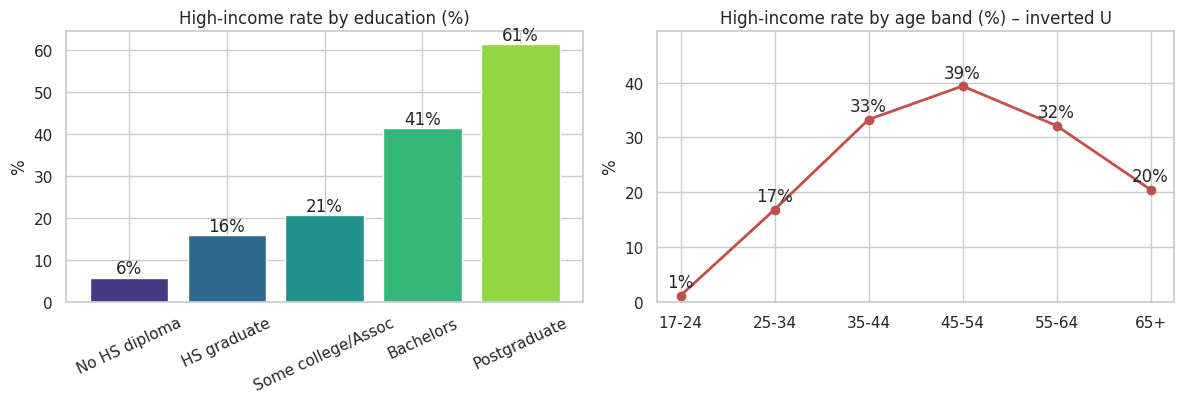

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
e = rate("edu_group").high_rate * 100; ax[0].bar(e.index, e.values, color=sns.color_palette("viridis", len(e))); ax[0].set(title="High-income rate by education (%)", ylabel="%"); ax[0].tick_params(axis="x", rotation=25)
[ax[0].text(i, v + 1, f"{v:.0f}%", ha="center") for i, v in enumerate(e.values)]
a_ = rate("age_band").high_rate * 100; ax[1].plot(a_.index.astype(str), a_.values, marker="o", lw=2, c="#c0504d"); ax[1].set(title="High-income rate by age band (%) – inverted U", ylabel="%")
[ax[1].text(i, v + 1.5, f"{v:.0f}%", ha="center") for i, v in enumerate(a_.values)]; ax[1].set_ylim(0, a_.max() + 10)
save("01_education_age")

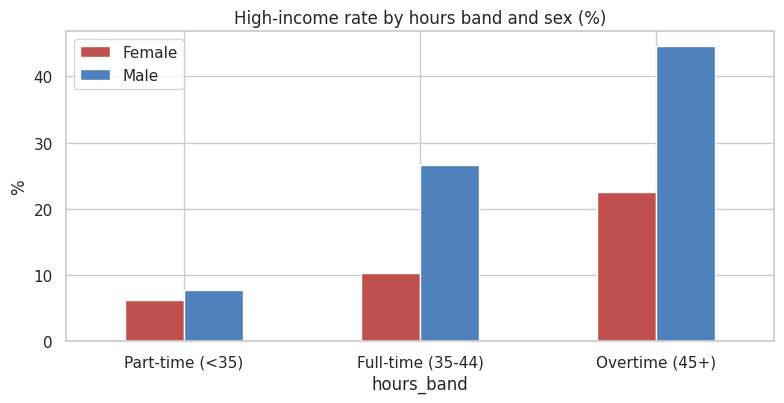

In [25]:
t = df.pivot_table(index="hours_band", columns="sex", values="high", aggfunc="mean", observed=True) * 100
t.plot(kind="bar", figsize=(8, 4.2), color=["#c0504d", "#4f81bd"]); plt.title("High-income rate by hours band and sex (%)"); plt.ylabel("%"); plt.xticks(rotation=0); plt.legend(title="")
save("02_sex_hours")

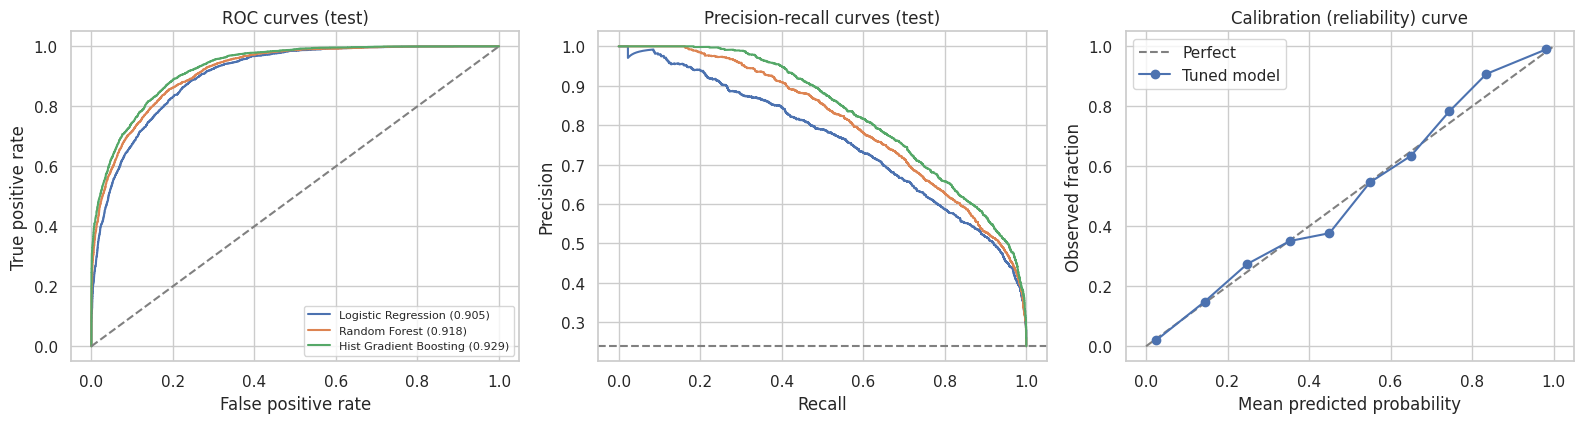

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for nme, c in zip(["Logistic Regression", "Random Forest", "Hist Gradient Boosting"], ["C0", "C1", "C2"]):
    p_ = fitted[nme].predict_proba(Xte)[:, 1]; fp_, tp_, _ = roc_curve(yte, p_); ax[0].plot(fp_, tp_, c=c, label=f"{nme} ({roc_auc_score(yte, p_):.3f})")
    pr_, rc_, _ = precision_recall_curve(yte, p_); ax[1].plot(rc_, pr_, c=c, label=nme)
ax[0].plot([0, 1], [0, 1], "--", c="gray"); ax[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(fontsize=8)
ax[1].axhline(yte.mean(), ls="--", c="gray"); ax[1].set(title="Precision-recall curves (test)", xlabel="Recall", ylabel="Precision")
ax[2].plot([0, 1], [0, 1], "--", c="gray", label="Perfect"); ax[2].plot(ct_.mean_pred, ct_.actual, marker="o", label="Tuned model"); ax[2].set(title="Calibration (reliability) curve", xlabel="Mean predicted probability", ylabel="Observed fraction"); ax[2].legend()
save("03_model_curves")

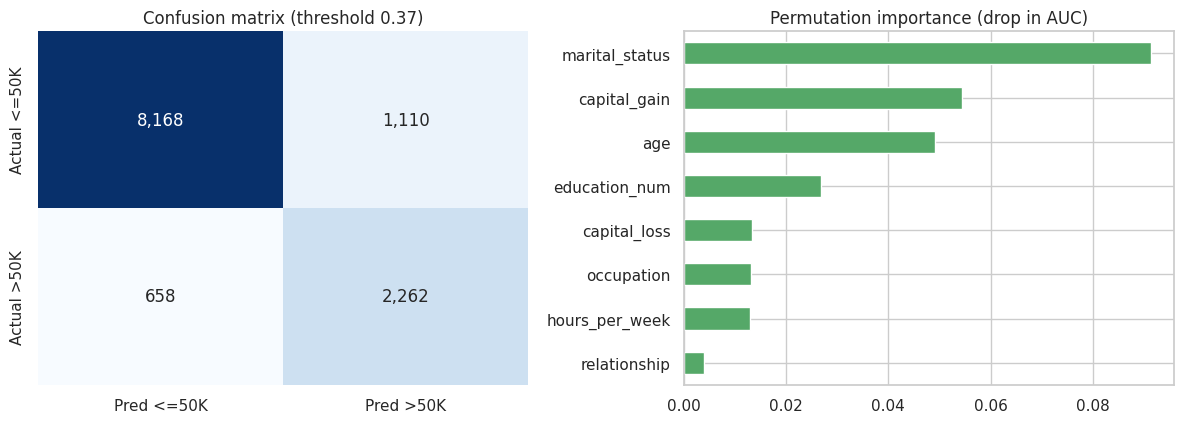

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sns.heatmap(pd.DataFrame(cm_, index=["Actual <=50K", "Actual >50K"], columns=["Pred <=50K", "Pred >50K"]), annot=True, fmt=",d", cmap="Blues", ax=ax[0], cbar=False); ax[0].set_title(f"Confusion matrix (threshold {thr:.2f})")
imp.head(8).sort_values().plot.barh(ax=ax[1], color="C2"); ax[1].set_title("Permutation importance (drop in AUC)")
save("04_confusion_importance")

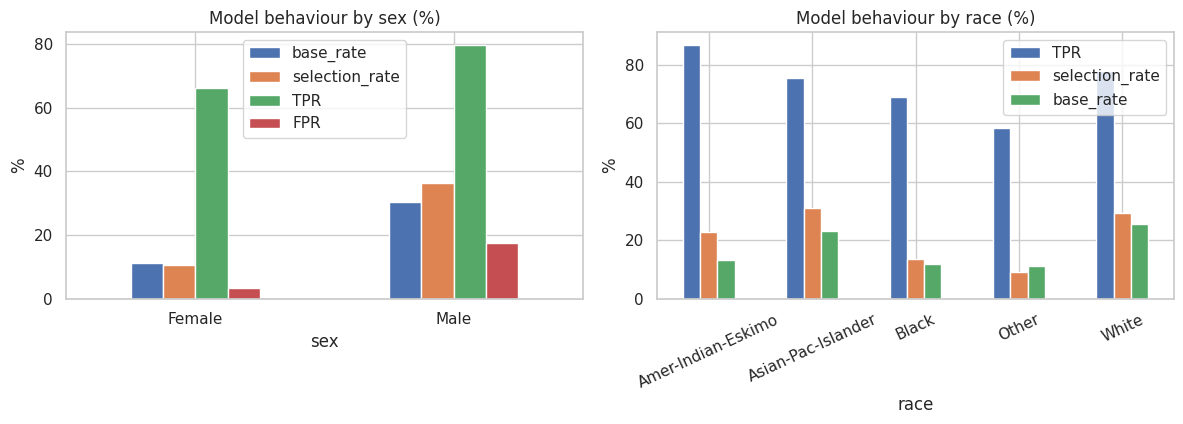

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sx = sub["sex"].set_index("sex")[["base_rate", "selection_rate", "TPR", "FPR"]] * 100; sx.plot(kind="bar", ax=ax[0]); ax[0].set(title="Model behaviour by sex (%)", ylabel="%"); ax[0].tick_params(axis="x", rotation=0)
rc = sub["race"].set_index("race")[["TPR", "selection_rate", "base_rate"]] * 100; rc.plot(kind="bar", ax=ax[1]); ax[1].set(title="Model behaviour by race (%)", ylabel="%"); ax[1].tick_params(axis="x", rotation=25)
save("05_subgroups")

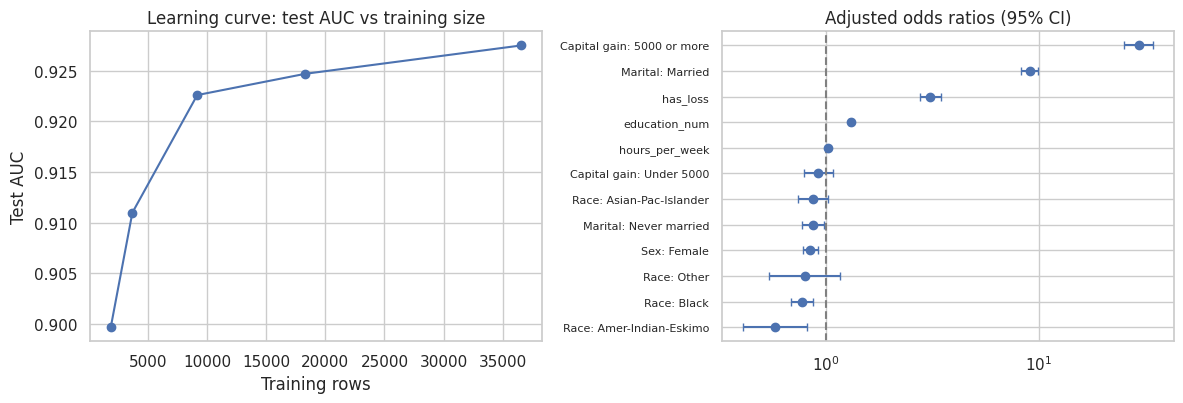

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(lc.train_rows, lc.test_auc, marker="o"); ax[0].set(title="Learning curve: test AUC vs training size", xlabel="Training rows", ylabel="Test AUC")
o2 = o.drop(index=[i for i in o.index if i in ("age", "age2")]).sort_values("OR")
ax[1].errorbar(o2.OR, range(len(o2)), xerr=[o2.OR - o2.lo, o2.hi - o2.OR], fmt="o", capsize=3); ax[1].axvline(1, c="gray", ls="--"); ax[1].set_yticks(range(len(o2))); ax[1].set_yticklabels(o2.index, fontsize=8); ax[1].set_xscale("log"); ax[1].set_title("Adjusted odds ratios (95% CI)")
save("06_learning_odds")

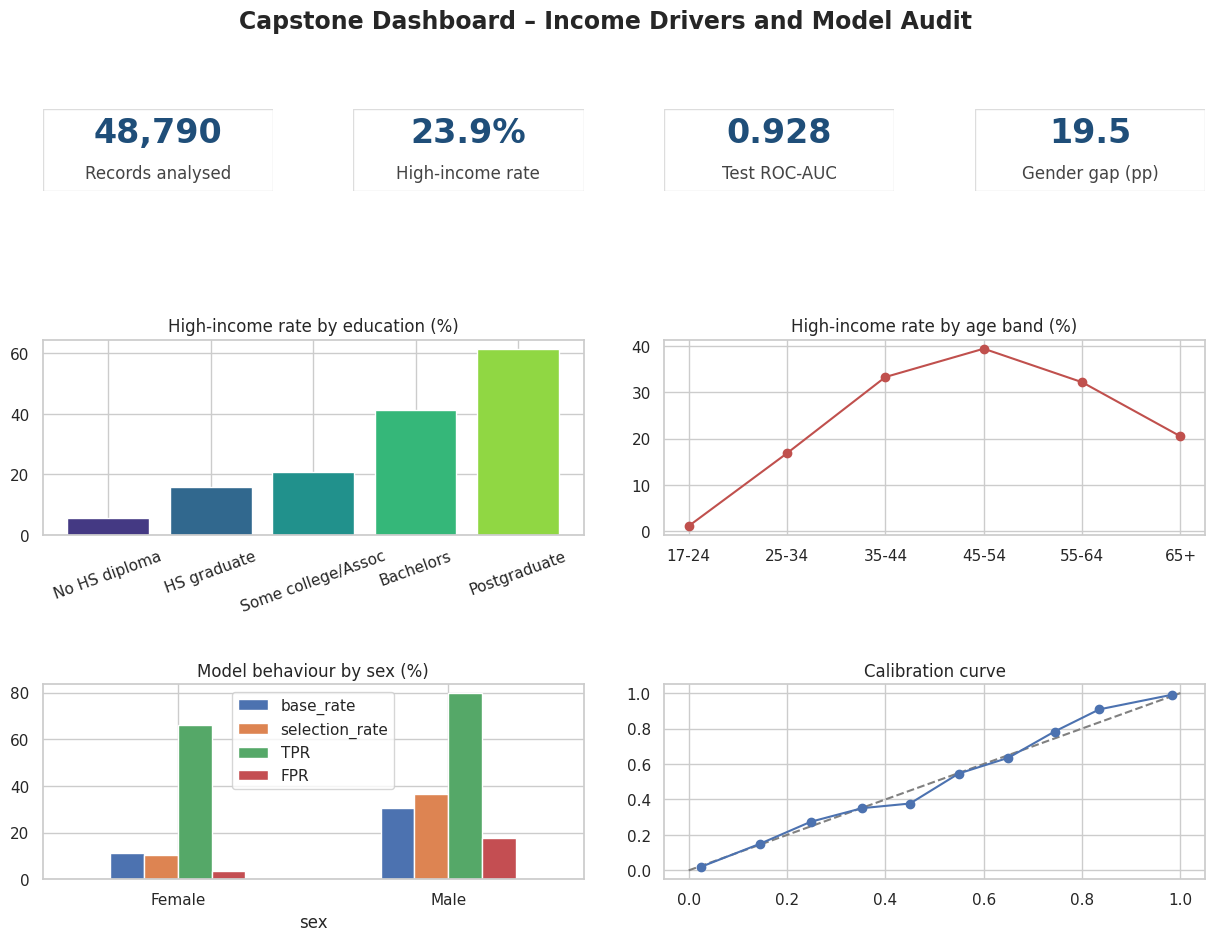

In [30]:
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(15, 10)); gs_ = GridSpec(3, 4, figure=fig, height_ratios=[.5, 1.2, 1.2], hspace=.95, wspace=.35)
k_ = [("Records analysed", f"{len(df):,}"), ("High-income rate", f"{df.high.mean():.1%}"), ("Test ROC-AUC", f"{roc_auc_score(yte, pb):.3f}"), ("Gender gap (pp)", f"{M['gap_pp']:.1f}")]
for i, (kk, vv) in enumerate(k_):
    a = fig.add_subplot(gs_[0, i]); a.axis("off"); a.text(.5, .6, vv, ha="center", fontsize=24, weight="bold", color="#1f4e79"); a.text(.5, .15, kk, ha="center", fontsize=12, color="#444"); a.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="#ddd", transform=a.transAxes))
a = fig.add_subplot(gs_[1, 0:2]); a.bar(e.index, e.values, color=sns.color_palette("viridis", len(e))); a.set_title("High-income rate by education (%)"); a.tick_params(axis="x", rotation=20)
a = fig.add_subplot(gs_[1, 2:4]); a.plot(a_.index.astype(str), a_.values, marker="o", c="#c0504d"); a.set_title("High-income rate by age band (%)")
a = fig.add_subplot(gs_[2, 0:2]); sx.plot(kind="bar", ax=a); a.set_title("Model behaviour by sex (%)"); a.tick_params(axis="x", rotation=0)
a = fig.add_subplot(gs_[2, 2:4]); a.plot([0, 1], [0, 1], "--", c="gray"); a.plot(ct_.mean_pred, ct_.actual, marker="o"); a.set_title("Calibration curve")
fig.suptitle("Capstone Dashboard – Income Drivers and Model Audit", fontsize=17, weight="bold", y=.98); save("00_dashboard")

## 8. Biases and Limitations (Data, Analysis and Model)
| Type | What it is here | Effect on conclusions |
|---|---|---|
| **Sampling / temporal bias** | 1994 US Census extract; nominal $50K threshold is not comparable with today's incomes; population, industries and norms have changed | Findings cannot be transferred to today or to other countries without validation |
| **Historical bias** | Patterns such as the gender gap reflect past labour-market conditions and discrimination | A model trained on this data reproduces them |
| **Representation bias** | Race groups other than White are small (Amer-Indian-Eskimo and Other < 1% each); Women are ~33% of rows | Subgroup estimates have wide uncertainty |
| **Measurement bias** | Capital gains top-coded at 99,999; age top-coded at 90; income is a binary cut-off, not the amount; unit of income (individual vs household) unclear | Information lost; boundary cases are noisy |
| **Selection bias** | Only people with positive income/hours are included (non-working people excluded) | Understates inequality and overstates average hours |
| **Missing-data bias** | `?` in workclass/occupation/country is non-random (those people earn less and work fewer hours) | Treated as 'Unknown' category; may hide heterogeneity |
| **Proxy bias** | Relationship, marital status, occupation and hours encode sex | Removing sex from the model does not remove sex-related effects |
| **Omitted-variable / bad controls** | No experience, industry, region, career interruptions; occupation and hours may themselves reflect unequal opportunity | 'Adjusted' gaps cannot be read as causal or as fair |
| **Statistical limitations** | Associations, not causation; many tests (mitigated by Holm correction); large n makes tiny effects 'significant' | Effect sizes and CIs must be read, not p-values alone |
| **Model limitations** | Class imbalance (about 3:1); probabilities are approximately but not perfectly calibrated; uncertain zone of mid-range predictions; performance depends on subgroup; no out-of-time test | Model suitable only for group-level planning |
| **Ethical risk** | Using such a model for individual decisions (lending, hiring) would risk automating historic disadvantage | Not recommended; any use requires fairness review and human oversight |

## 9. Insights, Recommendations and Future Scope
**Insights.** (see printed numbers above and the report) education and hours worked are the strongest actionable factors; household status and age are strong but not actionable; the sex gap is large, partly explained by observed factors and partly unexplained; the model predicts well without sex or race but still reproduces group differences through proxies.

**Recommendations**
1. Use the model only for **aggregate planning** (e.g. estimating where upskilling programmes could shift the distribution), never for individual decisions.
2. Prioritise **education and training pathways** and support for **access to full-time work**, the two largest modifiable associations.
3. Before deployment, **re-validate on current data**, monitor subgroup metrics, and decide with stakeholders which fairness criterion applies.
4. Report uncertainty (CIs, calibration) with every output and keep a human in the loop for borderline predictions.
5. Collect richer, current data (experience, industry, region, hours history).

**Future scope.** Temporal validation on newer census (ACS) data; causal methods (matching, difference-in-differences, instrumental variables) for education effects; fairness-constrained learning; SHAP-based explanations; regression on actual income amount; monitoring dashboard.

In [31]:
json.dump(M, open("data/metrics.json", "w"), indent=1, default=float); print("metrics.json saved:", len(M), "entries")

metrics.json saved: 127 entries
